## 1. IMPORTS

In [1]:
import os, hashlib, random, time
import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.feature import hog
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from tqdm.notebook import tqdm
%matplotlib inline

## 2. PARAMÈTRES (change seulement les chemins)

In [25]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# --- Chemins ---
BASE_DIR = r"C:\Users\hp\Desktop\SmartWaste"
DATA_DIR = os.path.join(BASE_DIR, "dataset")      # dossier avec les 6 classes
OUTPUT_DIR = os.path.join(BASE_DIR, "output")     # modèle + figures
TEST_IMAGE = os.path.join(BASE_DIR, "test.jpg.png")  # une image pour tester à la fin
os.makedirs(OUTPUT_DIR, exist_ok=True)

# --- Taille des images ---
IMG_SIZE = (128, 128)

# --- Paramètres HOG ---
HOG_ORIENTATIONS = 9
HOG_PIXELS_PER_CELL = (16, 16)
HOG_CELLS_PER_BLOCK = (2, 2)

# --- Paramètres de la couleur (nombre de barres de chaque histogramme) ---
BINS_H = 16
BINS_S = 8
BINS_V = 8

## 3. DONNÉES : trouver les classes et lister les images

In [3]:
# 3.1 Trouver le dossier qui contient directement les dossiers de classes
ROOT = None
for dossier, sous_dossiers, fichiers in os.walk(DATA_DIR):
    nb_dossiers_avec_images = 0
    for d in sous_dossiers:
        contenu = os.listdir(os.path.join(dossier, d))
        for nom in contenu:
            if nom.lower().endswith((".jpg", ".jpeg", ".png")):
                nb_dossiers_avec_images = nb_dossiers_avec_images + 1
                break
    if nb_dossiers_avec_images >= 2:
        ROOT = dossier
        break

if ROOT is None:
    raise FileNotFoundError("Dossier de classes introuvable, vérifie DATA_DIR")

# 3.2 Liste des classes
CLASSES = []
for d in sorted(os.listdir(ROOT)):
    if os.path.isdir(os.path.join(ROOT, d)):
        CLASSES.append(d)
print("Dossier :", ROOT)
print("Classes :", CLASSES)

# 3.3 Inventaire de toutes les images
chemins = []
labels = []
for cls in CLASSES:
    dossier = os.path.join(ROOT, cls)
    for nom in os.listdir(dossier):
        if nom.lower().endswith((".jpg", ".jpeg", ".png")):
            chemins.append(os.path.join(dossier, nom))
            labels.append(cls)

df = pd.DataFrame({"path": chemins, "label": labels})
print("Images trouvées :", len(df))
print(df["label"].value_counts())

Dossier : C:\Users\hp\Desktop\SmartWaste\dataset
Classes : ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Images trouvées : 2527
label
paper        594
glass        501
plastic      482
metal        410
cardboard    403
trash        137
Name: count, dtype: int64


## 4. NETTOYAGE

In [4]:
# 4.1 Supprimer les images illisibles ou trop petites
valides = []
for p in tqdm(df["path"], desc="Vérification"):
    img = cv2.imread(p)
    if img is None:
        valides.append(False)
    elif min(img.shape[:2]) < 32:
        valides.append(False)
    else:
        valides.append(True)

df["valid"] = valides
print("Images corrompues supprimées :", (~df["valid"]).sum())
df = df[df["valid"]].drop(columns="valid")

# 4.2 Supprimer les doublons exacts (hash MD5 du fichier)
hashes = []
for p in tqdm(df["path"], desc="Doublons"):
    with open(p, "rb") as fichier:
        hashes.append(hashlib.md5(fichier.read()).hexdigest())

df["hash"] = hashes
avant = len(df)
df = df.drop_duplicates(subset="hash").drop(columns="hash").reset_index(drop=True)
print("Doublons supprimés :", avant - len(df))
print("Images restantes :", len(df))

Vérification:   0%|          | 0/2527 [00:00<?, ?it/s]

Images corrompues supprimées : 0


Doublons:   0%|          | 0/2527 [00:00<?, ?it/s]

Doublons supprimés : 3
Images restantes : 2524


## 5. GRAPHIQUES DES DONNÉES

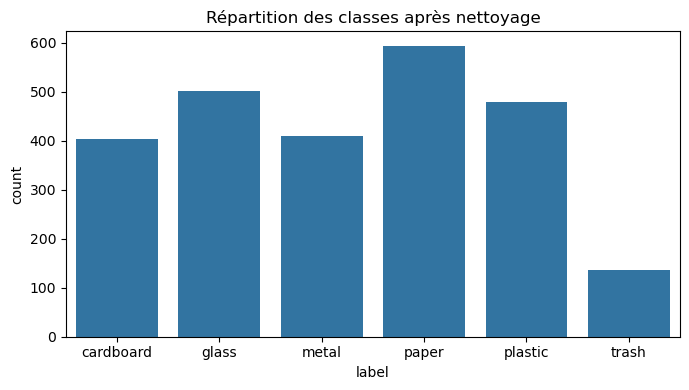

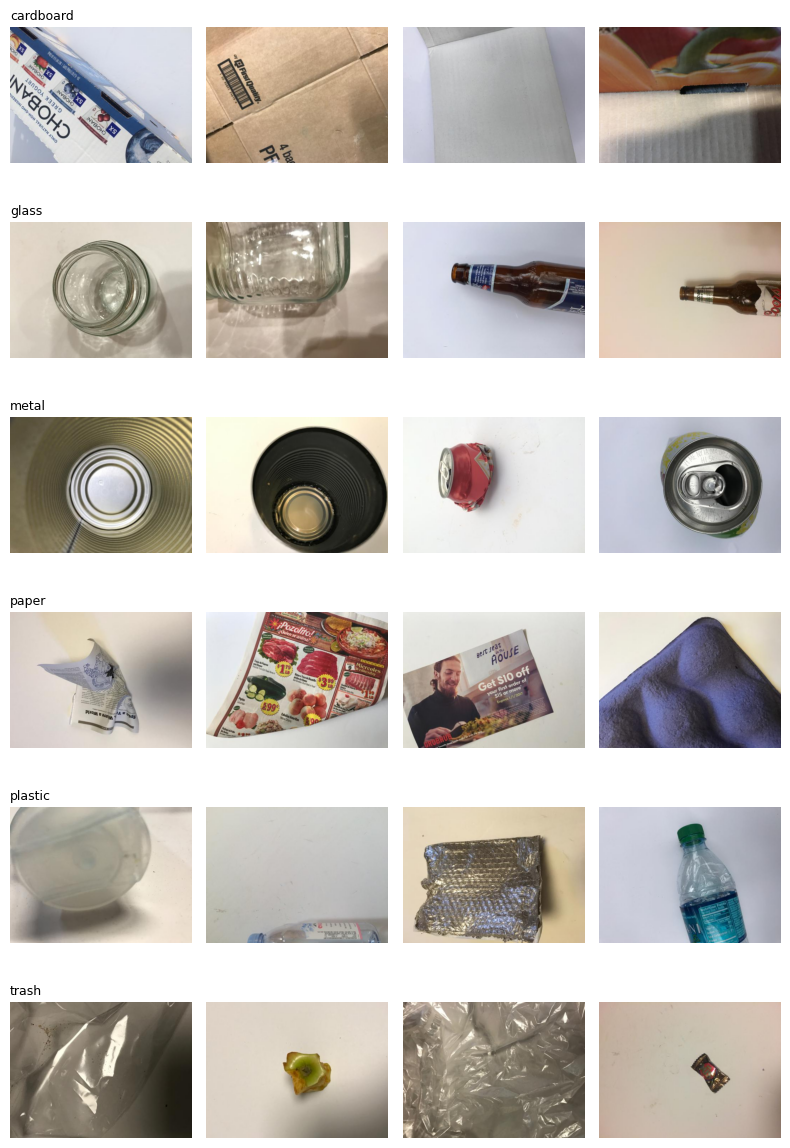

In [5]:
# 5.1 Répartition des classes
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="label", order=CLASSES)
plt.title("Répartition des classes après nettoyage")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "repartition_classes.png"), dpi=150)
plt.show()

# 5.2 Quelques images par classe
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(8, 2 * len(CLASSES)))
for i in range(len(CLASSES)):
    cls = CLASSES[i]
    exemples = df[df["label"] == cls].sample(4, random_state=SEED)["path"].tolist()
    for j in range(4):
        image = cv2.cvtColor(cv2.imread(exemples[j]), cv2.COLOR_BGR2RGB)
        axes[i, j].imshow(image)
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(cls, loc="left", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "apercu_images.png"), dpi=120)
plt.show()

## 6. SÉPARATION TRAIN / VALIDATION / TEST (avant toute extraction)

In [6]:
le = LabelEncoder()
le.fit(CLASSES)
df["y"] = le.transform(df["label"])

# 70 % train, 15 % validation, 15 % test (stratifié = mêmes proportions de classes)
train_idx, temp_idx = train_test_split(df.index, test_size=0.30,
                                       stratify=df["y"], random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50,
                                     stratify=df.loc[temp_idx, "y"], random_state=SEED)

df["split"] = "train"
df.loc[val_idx, "split"] = "val"
df.loc[test_idx, "split"] = "test"
print(df["split"].value_counts())

split
train    1766
test      379
val       379
Name: count, dtype: int64


## 7. EXTRACTION DES CARACTÉRISTIQUES (HOG + couleur)

Pour chaque image :
- **HOG** (forme / contours) calculé sur l'image en gris avec CLAHE
- **Histogramme HSV** (couleur) : 3 petits histogrammes H, S, V
- Les deux sont collés l'un après l'autre pour faire un seul vecteur

Pour les images du **train uniquement**, on ajoute 3 copies modifiées : miroir, rotation de 10°, plus lumineuse.

In [7]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
centre = (IMG_SIZE[0] / 2, IMG_SIZE[1] / 2)
matrice_rotation = cv2.getRotationMatrix2D(centre, 10, 1.0)

X_list = []        # les vecteurs de caractéristiques
y_list = []        # les classes (0 à 5)
split_list = []    # "train", "val" ou "test"
groupe_list = []   # numéro de l'image d'origine (sert à la validation croisée)

for i in tqdm(range(len(df)), desc="Extraction"):
    chemin = df.loc[i, "path"]
    classe = df.loc[i, "y"]
    partie = df.loc[i, "split"]

    # Lire et redimensionner
    img = cv2.imread(chemin)
    img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)

    # Liste des versions de l'image
    versions = [img]
    if partie == "train":
        versions.append(cv2.flip(img, 1))                                    # miroir
        versions.append(cv2.warpAffine(img, matrice_rotation, IMG_SIZE,
                                       borderMode=cv2.BORDER_REFLECT))       # rotation
        versions.append(cv2.convertScaleAbs(img, alpha=1.0, beta=30))        # plus lumineuse

    for version in versions:
        # --- Forme : HOG ---
        gris = cv2.cvtColor(version, cv2.COLOR_BGR2GRAY)
        gris = clahe.apply(gris)
        vecteur_hog = hog(gris, orientations=HOG_ORIENTATIONS,
                          pixels_per_cell=HOG_PIXELS_PER_CELL,
                          cells_per_block=HOG_CELLS_PER_BLOCK,
                          block_norm="L2-Hys")

        # --- Couleur : histogrammes H, S, V ---
        hsv = cv2.cvtColor(version, cv2.COLOR_BGR2HSV)
        hist_h = cv2.calcHist([hsv], [0], None, [BINS_H], [0, 180]).flatten()
        hist_s = cv2.calcHist([hsv], [1], None, [BINS_S], [0, 256]).flatten()
        hist_v = cv2.calcHist([hsv], [2], None, [BINS_V], [0, 256]).flatten()
        hist_h = hist_h / hist_h.sum()
        hist_s = hist_s / hist_s.sum()
        hist_v = hist_v / hist_v.sum()

        # --- Coller tout ensemble ---
        vecteur = np.concatenate([vecteur_hog, hist_h, hist_s, hist_v])
        X_list.append(vecteur)
        y_list.append(classe)
        split_list.append(partie)
        groupe_list.append(i)

X_all = np.array(X_list, dtype=np.float32)
y_all = np.array(y_list)
split_all = np.array(split_list)
groupe_all = np.array(groupe_list)

# Séparer en train / val / test
X_train, y_train, g_train = X_all[split_all == "train"], y_all[split_all == "train"], groupe_all[split_all == "train"]
X_val, y_val = X_all[split_all == "val"], y_all[split_all == "val"]
X_test, y_test = X_all[split_all == "test"], y_all[split_all == "test"]

print("Train (avec augmentation) :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)
print("Taille du vecteur :", X_train.shape[1], "(HOG + couleur)")

Extraction:   0%|          | 0/2524 [00:00<?, ?it/s]

Train (avec augmentation) : (7064, 1796)
Validation : (379, 1796)
Test : (379, 1796)
Taille du vecteur : 1796 (HOG + couleur)


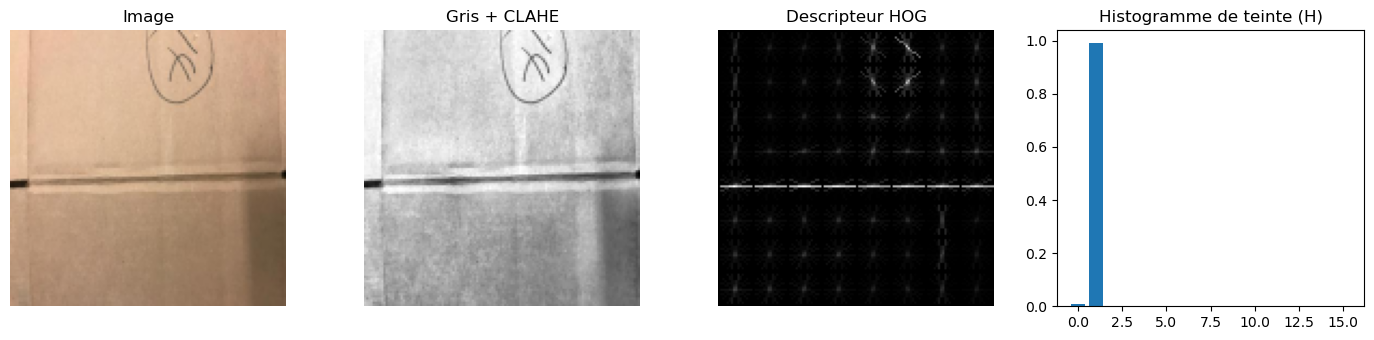

In [8]:
# Graphique : exemple de HOG et de couleur sur la première image du train
chemin_ex = df[df["split"] == "train"].iloc[0]["path"]
img_ex = cv2.resize(cv2.imread(chemin_ex), IMG_SIZE, interpolation=cv2.INTER_AREA)
gris_ex = clahe.apply(cv2.cvtColor(img_ex, cv2.COLOR_BGR2GRAY))
_, hog_image = hog(gris_ex, orientations=HOG_ORIENTATIONS,
                   pixels_per_cell=HOG_PIXELS_PER_CELL,
                   cells_per_block=HOG_CELLS_PER_BLOCK,
                   block_norm="L2-Hys", visualize=True)
hsv_ex = cv2.cvtColor(img_ex, cv2.COLOR_BGR2HSV)
hist_ex = cv2.calcHist([hsv_ex], [0], None, [BINS_H], [0, 180]).flatten()

fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
ax[0].imshow(cv2.cvtColor(img_ex, cv2.COLOR_BGR2RGB)); ax[0].set_title("Image"); ax[0].axis("off")
ax[1].imshow(gris_ex, cmap="gray"); ax[1].set_title("Gris + CLAHE"); ax[1].axis("off")
ax[2].imshow(hog_image, cmap="gray"); ax[2].set_title("Descripteur HOG"); ax[2].axis("off")
ax[3].bar(range(BINS_H), hist_ex / hist_ex.sum()); ax[3].set_title("Histogramme de teinte (H)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "exemple_hog_couleur.png"), dpi=150)
plt.show()

## 8. ENTRAÎNEMENT RAPIDE

**Pourquoi la version précédente bloquait :** le GridSearch faisait 60 entraînements, et chaque entraînement refaisait StandardScaler + PCA sur 7064 images × 1796 valeurs. Sur Windows, `n_jobs=-1` peut en plus bloquer Jupyter.

**Ce qu'on change ici :**
1. Scaler + PCA sont faits **une seule fois** (PCA fixée à 150 composantes, méthode rapide)
2. Pas de GridSearch : une petite **boucle simple** avec 6 essais, évalués sur la validation, avec le temps affiché pour voir que ça avance
3. Le SVM avec probabilités (le plus lent) n'est entraîné **qu'une seule fois**, à la fin

In [9]:
# 8.1 Standardisation puis PCA (une seule fois)
debut = time.time()

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

pca = PCA(n_components=150, svd_solver="randomized", random_state=SEED)
X_train_p = pca.fit_transform(X_train_s)
X_val_p = pca.transform(X_val_s)
X_test_p = pca.transform(X_test_s)

print("Avant PCA :", X_train.shape[1], "valeurs par image")
print("Après PCA :", X_train_p.shape[1], "valeurs par image")
print("Information gardée :", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")
print("Temps :", round(time.time() - debut, 1), "secondes")

Avant PCA : 1796 valeurs par image
Après PCA : 150 valeurs par image
Information gardée : 75.2 %
Temps : 1.2 secondes


In [10]:
# 8.2 Recherche des meilleurs réglages (C et gamma) sur la VALIDATION
liste_C = [1, 10, 100]
liste_gamma = ["scale", 0.001]

meilleur_f1 = 0
meilleur_C = 1
meilleur_gamma = "scale"

for C in liste_C:
    for gamma in liste_gamma:
        debut = time.time()

        svm = SVC(kernel="rbf", C=C, gamma=gamma, class_weight="balanced", random_state=SEED)
        svm.fit(X_train_p, y_train)

        pred = svm.predict(X_val_p)
        f1 = f1_score(y_val, pred, average="macro")
        duree = round(time.time() - debut, 1)

        print("C =", C, "| gamma =", gamma, "| F1 validation =", round(f1, 4), "| temps =", duree, "s")

        if f1 > meilleur_f1:
            meilleur_f1 = f1
            meilleur_C = C
            meilleur_gamma = gamma

print("")
print("Meilleur choix : C =", meilleur_C, "| gamma =", meilleur_gamma, "| F1 =", round(meilleur_f1, 4))

C = 1 | gamma = scale | F1 validation = 0.6764 | temps = 8.0 s
C = 1 | gamma = 0.001 | F1 validation = 0.6737 | temps = 8.9 s
C = 10 | gamma = scale | F1 validation = 0.6713 | temps = 8.7 s
C = 10 | gamma = 0.001 | F1 validation = 0.6551 | temps = 12.3 s
C = 100 | gamma = scale | F1 validation = 0.6713 | temps = 8.2 s
C = 100 | gamma = 0.001 | F1 validation = 0.6551 | temps = 10.9 s

Meilleur choix : C = 1 | gamma = scale | F1 = 0.6764


In [12]:
# 8.3 Modèle final avec les meilleurs réglages (avec probabilités, entraîné une seule fois)
debut = time.time()
model = SVC(kernel="rbf", C=meilleur_C, gamma=meilleur_gamma, class_weight="balanced",
            probability=True, random_state=SEED)
model.fit(X_train_p, y_train)
print("Modèle final entraîné en", round(time.time() - debut, 1), "secondes")

Modèle final entraîné en 42.5 secondes


## 9. RÉSULTATS : validation puis test final

In [13]:
# 9.1 Validation
pred_val = model.predict(X_val_p)
print("===== VALIDATION =====")
print("Accuracy   :", round(accuracy_score(y_val, pred_val), 4))
print("F1-macro   :", round(f1_score(y_val, pred_val, average="macro"), 4))
print(classification_report(y_val, pred_val, target_names=le.classes_, digits=3))

# 9.2 Test (résultat final)
y_pred = model.predict(X_test_p)
print("===== TEST (résultat final) =====")
print("Accuracy   :", round(accuracy_score(y_test, y_pred), 4))
print("F1-macro   :", round(f1_score(y_test, y_pred, average="macro"), 4))
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=3))

===== VALIDATION =====
Accuracy   : 0.6834
F1-macro   : 0.6764
              precision    recall  f1-score   support

   cardboard      0.745     0.672     0.707        61
       glass      0.712     0.627     0.667        75
       metal      0.672     0.694     0.683        62
       paper      0.758     0.809     0.783        89
     plastic      0.544     0.597     0.570        72
       trash      0.650     0.650     0.650        20

    accuracy                          0.683       379
   macro avg      0.680     0.675     0.676       379
weighted avg      0.686     0.683     0.684       379

===== TEST (résultat final) =====
Accuracy   : 0.6332
F1-macro   : 0.6125
              precision    recall  f1-score   support

   cardboard      0.745     0.683     0.713        60
       glass      0.560     0.553     0.556        76
       metal      0.544     0.508     0.525        61
       paper      0.732     0.798     0.763        89
     plastic      0.584     0.625     0.604      

## 10. GRAPHIQUES DES RÉSULTATS

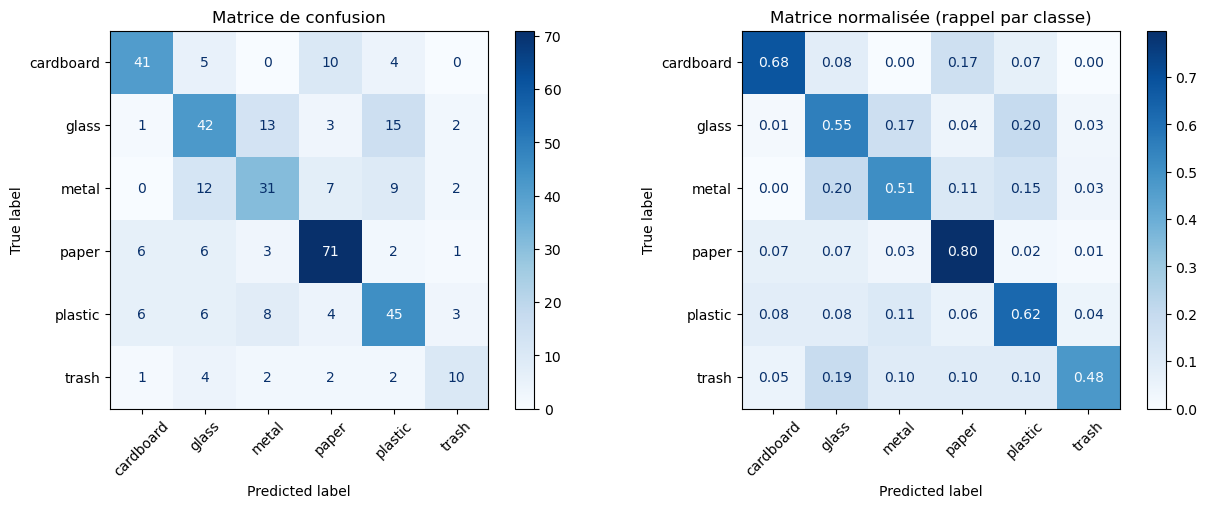

Nombre d'erreurs affichées : 8


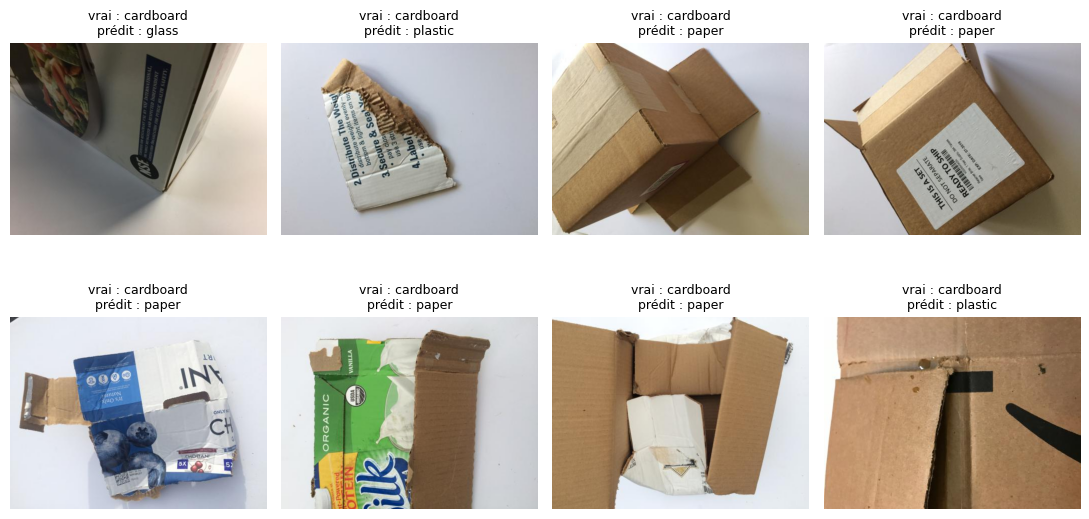

In [14]:
# 10.1 Matrices de confusion
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_,
                                        ax=axes[0], cmap="Blues", xticks_rotation=45)
axes[0].set_title("Matrice de confusion")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_,
                                        normalize="true", values_format=".2f",
                                        ax=axes[1], cmap="Blues", xticks_rotation=45)
axes[1].set_title("Matrice normalisée (rappel par classe)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "matrice_confusion.png"), dpi=150)
plt.show()

# 10.2 Images mal classées
test_df = df[df["split"] == "test"].reset_index(drop=True)
erreurs = np.where(y_pred != y_test)[0][:8]
print("Nombre d'erreurs affichées :", len(erreurs))

if len(erreurs) > 0:
    fig, axes = plt.subplots(2, 4, figsize=(11, 6))
    axes = axes.ravel()
    for k in range(8):
        axes[k].axis("off")
    for k in range(len(erreurs)):
        idx = erreurs[k]
        image = cv2.cvtColor(cv2.imread(test_df.loc[idx, "path"]), cv2.COLOR_BGR2RGB)
        axes[k].imshow(image)
        axes[k].set_title("vrai : " + le.classes_[y_test[idx]] + "\nprédit : " + le.classes_[y_pred[idx]], fontsize=9)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "erreurs.png"), dpi=130)
    plt.show()

## 11. SAUVEGARDE DU MODÈLE ET TEST SUR UNE NOUVELLE IMAGE

In [26]:
# 11.1 Sauvegarde (le scaler, la PCA et le SVM sont sauvegardés ensemble, pour l'API Flask)
paquet = {
    "scaler": scaler,
    "pca": pca,
    "model": model,
    "classes": le.classes_,
    "img_size": IMG_SIZE,
    "hog_orientations": HOG_ORIENTATIONS,
    "hog_pixels_per_cell": HOG_PIXELS_PER_CELL,
    "hog_cells_per_block": HOG_CELLS_PER_BLOCK,
    "bins_h": BINS_H, "bins_s": BINS_S, "bins_v": BINS_V,
}
joblib.dump(paquet, os.path.join(OUTPUT_DIR, "modele_hog_couleur_svm.joblib"))
print("Modèle sauvegardé dans :", OUTPUT_DIR)

# 11.2 Prédiction sur une nouvelle image
if os.path.exists(TEST_IMAGE):
    img = cv2.imread(TEST_IMAGE)
    img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)

    gris = clahe.apply(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY))
    vecteur_hog = hog(gris, orientations=HOG_ORIENTATIONS,
                      pixels_per_cell=HOG_PIXELS_PER_CELL,
                      cells_per_block=HOG_CELLS_PER_BLOCK,
                      block_norm="L2-Hys")

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hist_h = cv2.calcHist([hsv], [0], None, [BINS_H], [0, 180]).flatten()
    hist_s = cv2.calcHist([hsv], [1], None, [BINS_S], [0, 256]).flatten()
    hist_v = cv2.calcHist([hsv], [2], None, [BINS_V], [0, 256]).flatten()
    hist_h = hist_h / hist_h.sum()
    hist_s = hist_s / hist_s.sum()
    hist_v = hist_v / hist_v.sum()

    vecteur = np.concatenate([vecteur_hog, hist_h, hist_s, hist_v]).reshape(1, -1)
    vecteur = scaler.transform(vecteur)
    vecteur = pca.transform(vecteur)

    proba = model.predict_proba(vecteur)[0]
    meilleur = np.argmax(proba)

    print("Classe prédite :", CLASSES[meilleur])
    print("Confiance :", round(proba[meilleur] * 100, 1), "%")
    for k in range(len(CLASSES)):
        print("  ", CLASSES[k], ":", round(proba[k] * 100, 1), "%")
else:
    print("Pas d'image de test. Change TEST_IMAGE dans la partie 2.")

Modèle sauvegardé dans : C:\Users\hp\Desktop\SmartWaste\output
Classe prédite : metal
Confiance : 86.7 %
   cardboard : 3.0 %
   glass : 2.9 %
   metal : 86.7 %
   paper : 6.9 %
   plastic : 0.4 %
   trash : 0.1 %
